
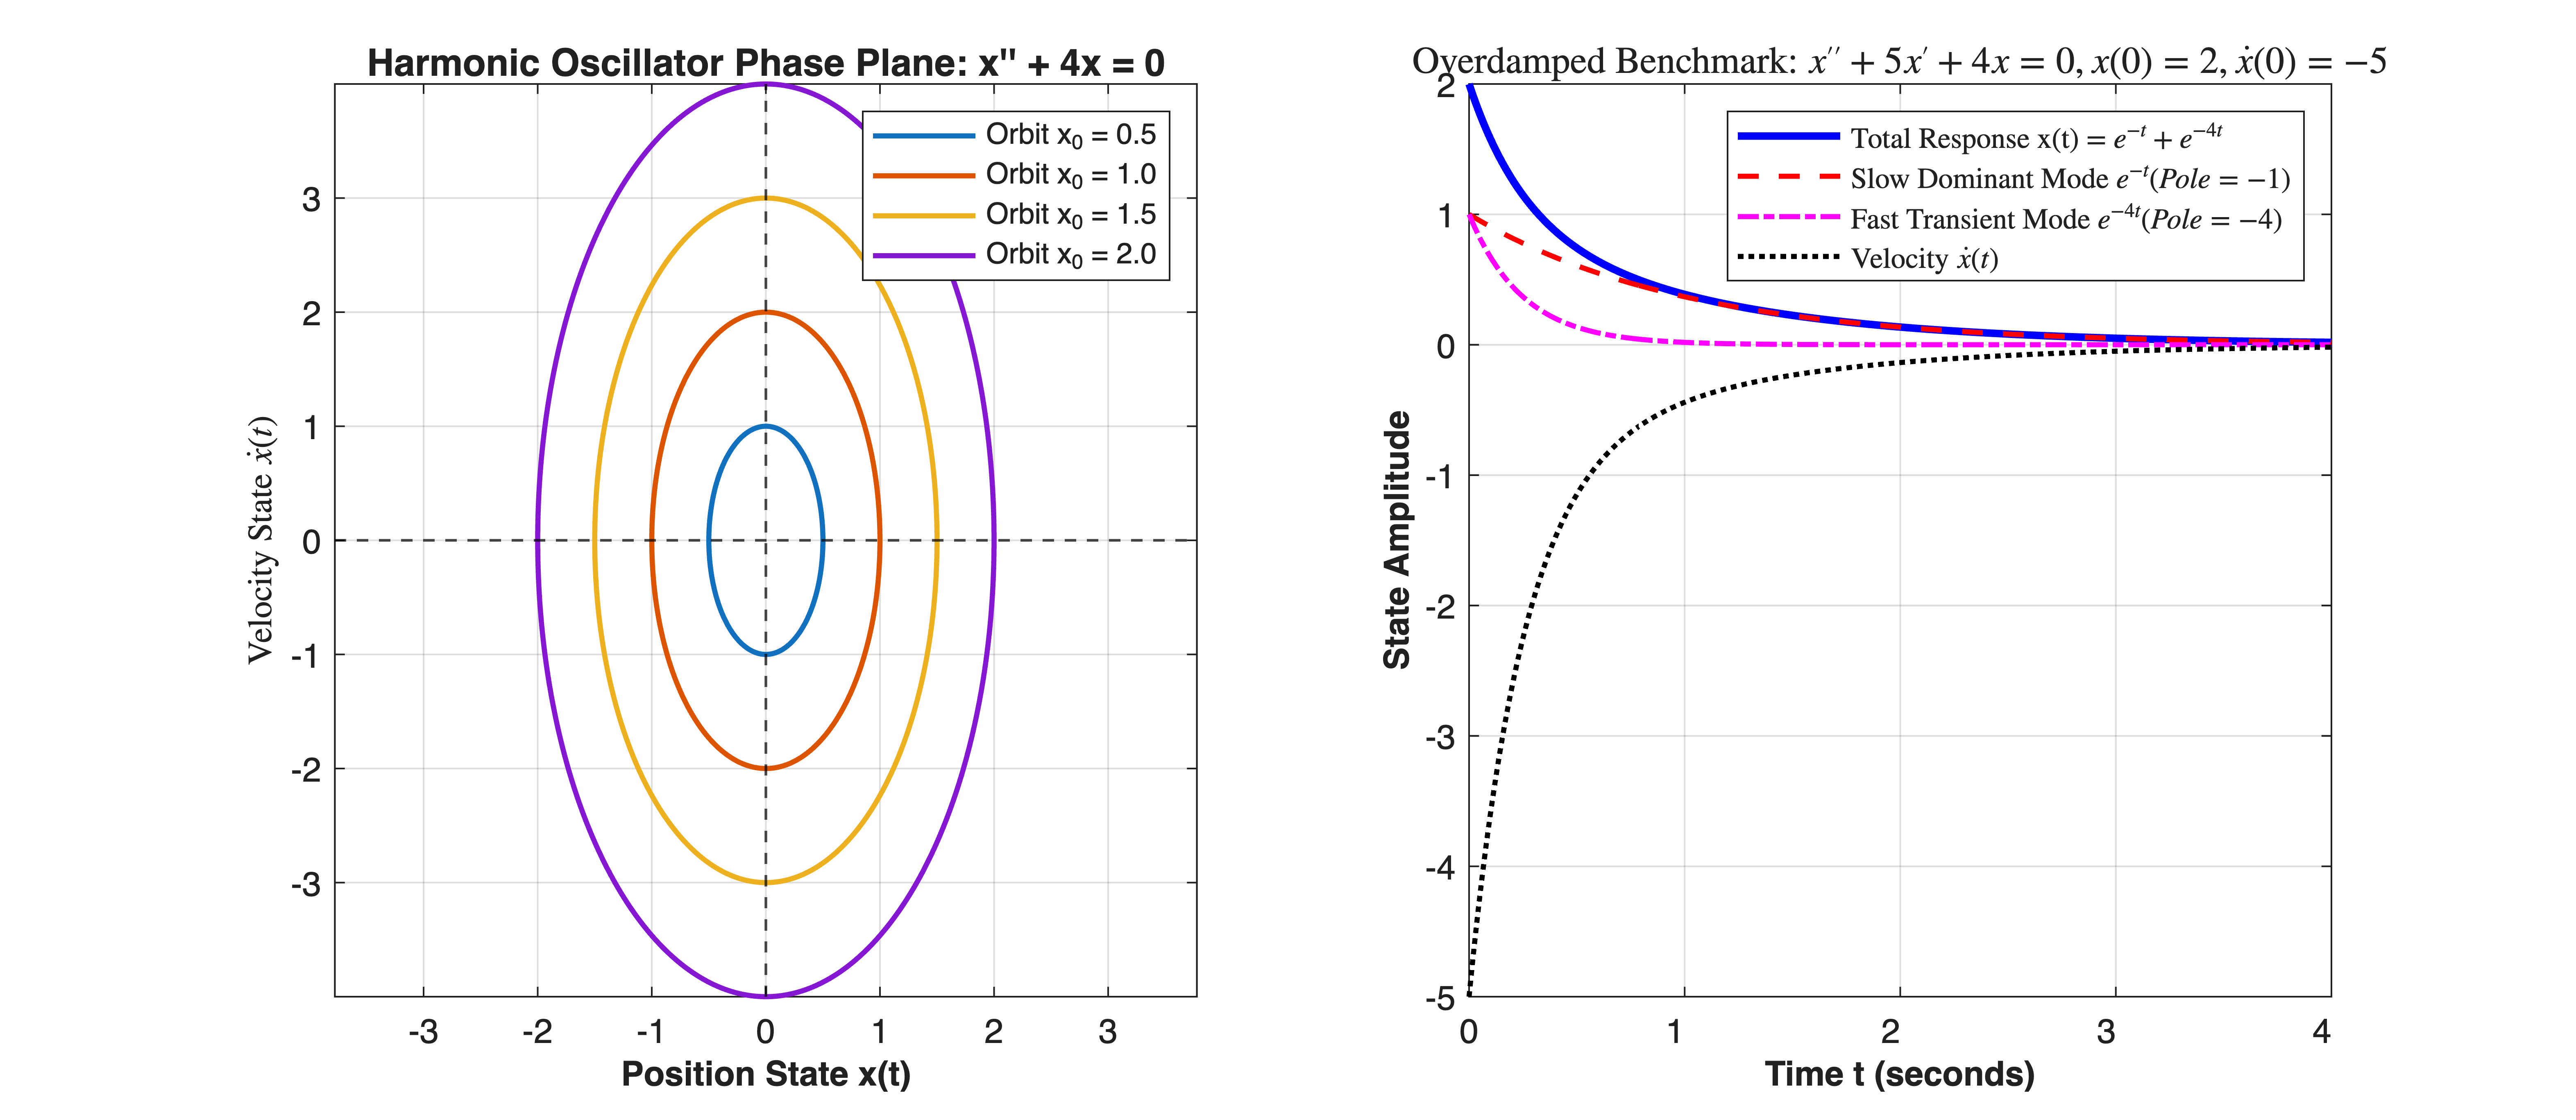

In [1]:
%% MIT 18.03 Lecture 11: Second-Order Physical Modeling & Homogeneous Dynamics
% Description: Simulates Mass-Spring-Damper systems:
%              1) Undamped harmonic oscillator: x'' + 4x = 0 (Center topology).
%              2) Overdamped system: x'' + 5x' + 4x = 0, x(0)=2, x'(0)=-5.
%
% % Required Toolboxes:
% %   - Base MATLAB (Core ODE numerical integration and matrix math).
% % Optional Toolboxes:
% %   - Control System Toolbox (For ss, tf, and pzmap LTI representation).
%
% % MBD Concept Mapping: Encapsulates standard 2nd-order plant dynamics mx'' + bx' + kx = u.
% %                      Extracts system poles from characteristic polynomial p(s) = ms^2 + bs + k.
% %                      Visualizes phase-plane trajectories (State Vector [x; x_dot]).


clear; clc; close all;


%% =========================================================================
%% Part 1: Undamped Harmonic Oscillator (x'' + 4x = 0)
%% =========================================================================
% Equation: x'' + omega^2 * x = 0 with omega = 2 rad/s, Period P = pi seconds
omega_osc = 2.0;
t_osc_span = [0, 2 * pi]; % 2 complete cycles
t_osc = linspace(t_osc_span(1), t_osc_span(2), 500);


% Initial states for various concentric closed orbits
x0_list = [0.5, 1.0, 1.5, 2.0];


figure('Color', [1 1 1], 'Position', [100, 100, 1150, 500]);


% Subplot 1: Phase Plane of Harmonic Oscillator (Center Orbit)
subplot(1, 2, 1);
hold on; grid on; box on;
xline(0, 'k--', 'LineWidth', 0.8, 'HandleVisibility', 'off');
yline(0, 'k--', 'LineWidth', 0.8, 'HandleVisibility', 'off');


for idx = 1:length(x0_list)
    x_init = x0_list(idx);
    % State trajectory: x(t) = x0*cos(omega*t), x_dot(t) = -omega*x0*sin(omega*t)
    x_traj = x_init * cos(omega_osc * t_osc);
    v_traj = -omega_osc * x_init * sin(omega_osc * t_osc);


    plot(x_traj, v_traj, 'LineWidth', 1.5, ...
        'DisplayName', sprintf('Orbit x_0 = %.1f', x_init));
end


axis equal;
xlabel('Position State x(t)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Velocity State $\dot{x}(t)$', 'FontSize', 10, 'FontWeight', 'bold','Interpreter','latex');
title('Harmonic Oscillator Phase Plane: x'''' + 4x = 0', 'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'northeast', 'FontSize', 8.5);


%% =========================================================================
%% Part 2: Overdamped Benchmark System (x'' + 5x' + 4x = 0)
%% =========================================================================
% Lecture benchmark: m = 1, b = 5, k = 4
% Characteristic equation: s^2 + 5s + 4 = (s + 1)(s + 4) = 0
% Roots: r1 = -1 (slow dominant mode), r2 = -4 (fast decaying mode)
% Initial condition: x(0) = 2, x'(0) = -5 -> x(t) = exp(-t) + exp(-4t)
t_bench_span = [0, 4.0];
t_eval = linspace(t_bench_span(1), t_bench_span(2), 400);


% Analytical decomposition
mode_slow = exp(-1.0 * t_eval);       % Slow mode: e^{-t}
mode_fast = exp(-4.0 * t_eval);       % Fast mode: e^{-4t}
x_exact   = mode_slow + mode_fast;    % General superposition: x(t) = e^{-t} + e^{-4t}
v_exact   = -mode_slow - 4*mode_fast; % Velocity: dx/dt = -e^{-t} - 4*e^{-4t}


% Subplot 2: Temporal Modal Decomposition and Response
subplot(1, 2, 2);
hold on; grid on; box on;


plot(t_eval, x_exact, 'b-', 'LineWidth', 2.2, ...
    'DisplayName', 'Total Response x(t) = $e^{-t} + e^{-4t}$');
plot(t_eval, mode_slow, 'r--', 'LineWidth', 1.5, ...
    'DisplayName', 'Slow Dominant Mode $e^{-t} (Pole = -1)$');
plot(t_eval, mode_fast, 'm-.', 'LineWidth', 1.5, ...
    'DisplayName', 'Fast Transient Mode $e^{-4t} (Pole = -4)$');
plot(t_eval, v_exact, 'k:', 'LineWidth', 1.5, ...
    'DisplayName', 'Velocity $\dot{x}(t)$');


xlabel('Time t (seconds)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('State Amplitude', 'FontSize', 10, 'FontWeight', 'bold');
title("Overdamped Benchmark: $x'' + 5x' + 4x = 0, x(0)=2, \dot{x}(0)=-5$", ...
    'FontSize', 11, 'FontWeight', 'bold','Interpreter','latex');
legend('Location', 'northeast', 'FontSize', 8.5, 'Interpreter','latex');
xlim([0, 4.0]);

In [2]:


fprintf('=== MIT 18.03 Lecture 11 2nd-Order Dynamics Diagnostics ===\n');

=== MIT 18.03 Lecture 11 2nd-Order Dynamics Diagnostics ===

In [3]:
fprintf('Harmonic Oscillator   : omega = %.2f rad/s, Period P = %.4f s\n', ...
    omega_osc, 2*pi/omega_osc);

Harmonic Oscillator   : omega = 2.00 rad/s, Period P = 3.1416 s

In [4]:
fprintf('Overdamped System     : Characteristic Equation: s^2 + 5s + 4 = 0\n');

Overdamped System     : Characteristic Equation: s^2 + 5s + 4 = 0

In [5]:
fprintf('System Poles          : s1 = -1.0, s2 = -4.0\n');

System Poles          : s1 = -1.0, s2 = -4.0

In [6]:
fprintf('Initial Conditions    : x(0) = 2.0, dx/dt(0) = -5.0\n');

Initial Conditions    : x(0) = 2.0, dx/dt(0) = -5.0

In [7]:
fprintf('Superposition Solution: x(t) = 1.0*exp(-t) + 1.0*exp(-4t)\n');

Superposition Solution: x(t) = 1.0*exp(-t) + 1.0*exp(-4t)

In [8]:
fprintf('===========================================================\n');